## Import Libraries

In [15]:
import numpy as np
import pandas as pd

from PIL import Image as PImage, ImageDraw as PImageDraw

from datasets import load_dataset

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances

### Silhouette `Dataset`
- [visualizedata/revolutionary_silhouettes](https://huggingface.co/datasets/visualizedata/revolutionary_silhouettes)

In [16]:
sil_ds = load_dataset("visualizedata/revolutionary_silhouettes", split="silhouetted", streaming=True)
sil_ds

IterableDataset({
    features: ['id', 'EDANid', 'imageURL', 'thumbnail', 'cx', 'cy', 'cw', 'ch', 'x0', 'y0', 'x1', 'y1', 'x2', 'y2', 'x3', 'y3', 'x4', 'y4', 'x5', 'y5', 'x6', 'y6', 'x7', 'y7', 'x8', 'y8', 'x9', 'y9', 'x10', 'y10', 'x11', 'y11', 'x12', 'y12', 'x13', 'y13', 'x14', 'y14', 'x15', 'y15', 'x16', 'y16', 'x17', 'y17', 'x18', 'y18', 'x19', 'y19', 'x20', 'y20', 'x21', 'y21', 'x22', 'y22', 'x23', 'y23', 'x24', 'y24', 'x25', 'y25', 'x26', 'y26', 'x27', 'y27', 'x28', 'y28', 'x29', 'y29', 'x30', 'y30', 'x31', 'y31', 'x32', 'y32', 'x33', 'y33', 'x34', 'y34', 'x35', 'y35', 'x36', 'y36', 'x37', 'y37', 'x38', 'y38', 'x39', 'y39', 'x40', 'y40', 'x41', 'y41', 'x42', 'y42', 'x43', 'y43', 'x44', 'y44', 'x45', 'y45', 'x46', 'y46', 'x47', 'y47', 'x48', 'y48', 'x49', 'y49', 'x50', 'y50', 'x51', 'y51', 'x52', 'y52', 'x53', 'y53', 'x54', 'y54', 'x55', 'y55', 'x56', 'y56', 'x57', 'y57', 'x58', 'y58', 'x59', 'y59', 'x60', 'y60', 'x61', 'y61', 'x62', 'y62', 'x63', 'y63', 'x64', 'y64', 'x65', 'y65'

In [17]:
xy_feats = [f for f in sil_ds.features.keys() if f.startswith(("x", "y"))]
non_xy_feats = [f for f in sil_ds.features.keys() if not f.startswith(("x", "y"))]

sil_xy_ds = sil_ds.select_columns(xy_feats)

sil_xy_df = sil_xy_ds.to_pandas()
sil_xy_df

<generator object IterableDataset.to_pandas at 0x1400f4d60>

In [18]:
sil_xy_df = pd.concat(sil_xy_ds.to_pandas(batched=True), ignore_index=True)
sil_xy_df

,x0,y0,x1,y1,x2,y2,x3,y3,x4,y4,...,x468,y468,x469,y469,x470,y470,x471,y471,x472,y472
0,726,950,726,946,726,942,726,938,722,934,...,730,970,730,966,730,962,730,958,730,954
1,730,990,730,986,726,982,722,978,722,974,...,730,1010,730,1006,730,1002,730,998,730,994
2,686,974,686,970,686,966,686,962,686,958,...,698,994,694,990,690,986,690,982,686,978
3,554,1038,554,1034,558,1030,558,1022,562,1018,...,542,1082,542,1074,546,1070,546,1062,550,1050
4,1286,582,1278,578,1282,578,1270,574,1274,574,...,1286,606,1286,602,1286,598,1286,594,1286,590
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1829,510,978,446,978,526,978,510,974,530,970,...,458,994,450,994,526,990,510,990,450,986
1830,350,986,418,986,354,982,458,982,418,978,...,350,1002,454,998,414,998,350,994,454,990
1831,542,1010,542,1006,542,998,538,990,538,982,...,522,1054,526,1046,530,1038,534,1030,538,1022
1832,382,1064,366,1052,358,1040,354,1028,350,1016,...,442,1096,430,1088,418,1080,406,1076,394,1072


### Clustering of Silhouettes

In [19]:
# Center points
xy_pairs = sil_xy_df.values.reshape(len(sil_xy_df), -1, 2)
xy_mean = xy_pairs.mean(axis=1).mean(axis=0)
xy_centered = (xy_pairs - xy_mean).reshape(len(sil_xy_df), -1)
sil_xy_cetered_df = pd.DataFrame(xy_centered, columns=sil_xy_df.columns)

In [20]:
n_clusters = 8

kmeans = KMeans(n_clusters=n_clusters, random_state=1010).fit(sil_xy_cetered_df)

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


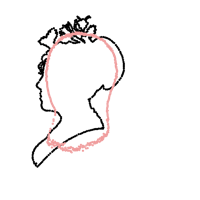

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


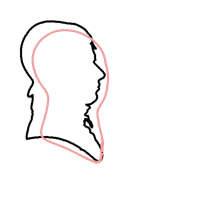

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


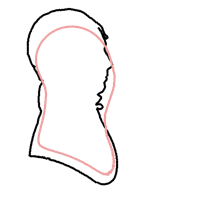

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


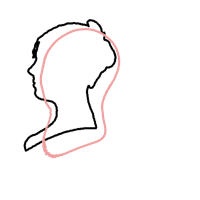

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


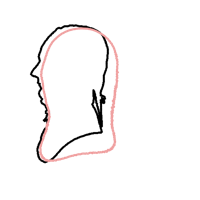

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


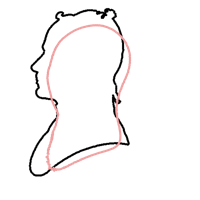

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


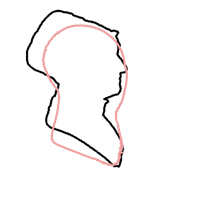

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


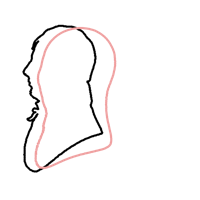

In [21]:
r = 10

for cidx in range(n_clusters):
  aimg = PImage.fromarray(255*np.ones((2000,2000,3), dtype=np.uint8)).convert("RGBA")
  aiw,aih = aimg.size
  draw = PImageDraw.Draw(aimg)

  cluster_sils = sil_xy_df.iloc[kmeans.labels_ == cidx]
  cluster_avg = cluster_sils.values.mean(axis=0).reshape(-1,2)
  dists = euclidean_distances([kmeans.cluster_centers_[cidx]], cluster_sils)
  by_dist = dists[0].argsort()

  for x,y in cluster_sils.values[by_dist[0]].reshape(-1,2):
    draw.ellipse((x-r, y-r, x+r, y+r), fill=(0,0,0))

  for x,y in kmeans.cluster_centers_[cidx].reshape(-1,2):
    x += xy_mean[0]
    y += xy_mean[1]
    draw.ellipse((x-r, y-r, x+r, y+r), fill=(220,0,0,100))
  display(aimg.resize((200, 200)))

GROUP 1 | drawings: 58 | typical width: 882 | typical height: 1472 | typical width/height: 0.61


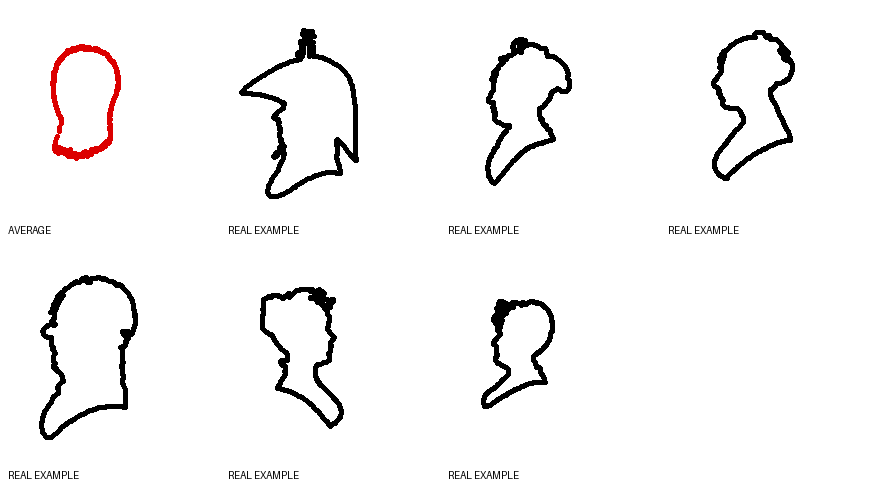

GROUP 2 | drawings: 335 | typical width: 840 | typical height: 1444 | typical width/height: 0.58


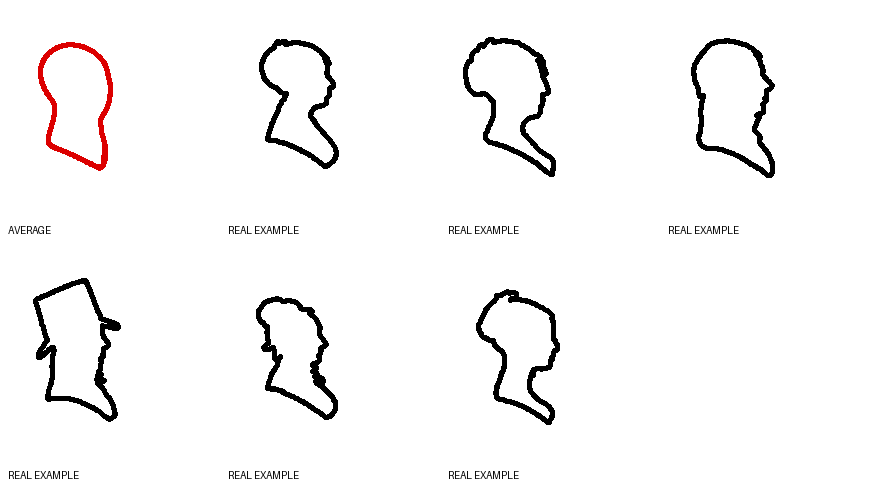

GROUP 3 | drawings: 341 | typical width: 876 | typical height: 1536 | typical width/height: 0.57


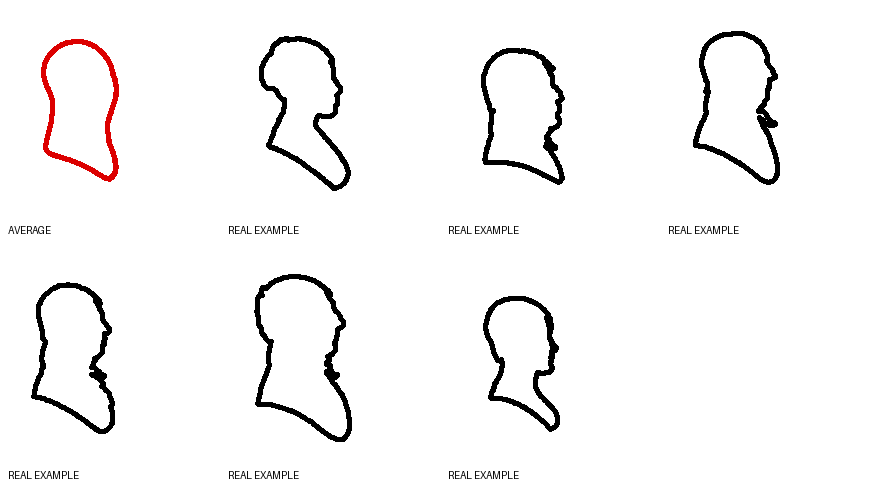

GROUP 4 | drawings: 284 | typical width: 894 | typical height: 1446 | typical width/height: 0.62


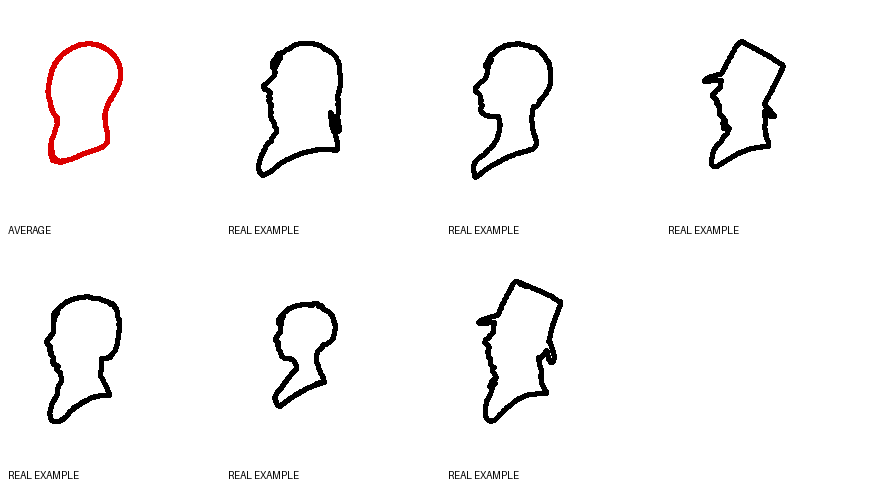

GROUP 5 | drawings: 94 | typical width: 900 | typical height: 1474 | typical width/height: 0.59


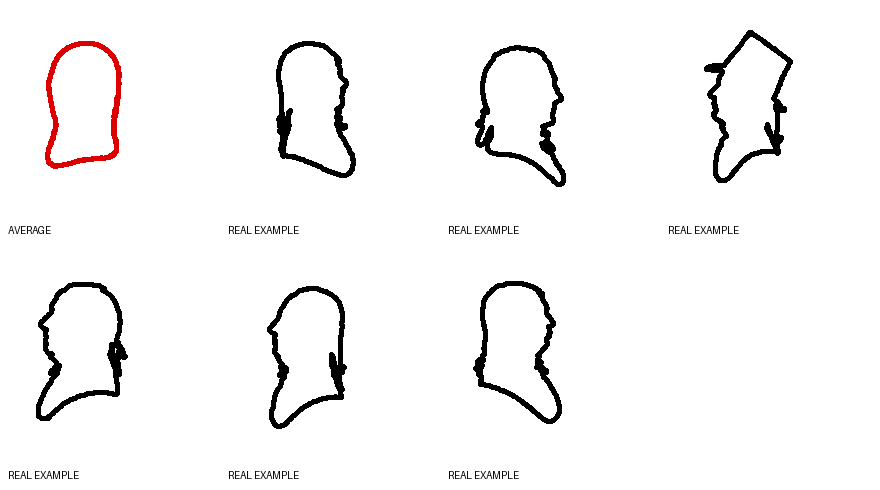

GROUP 6 | drawings: 265 | typical width: 928 | typical height: 1552 | typical width/height: 0.60


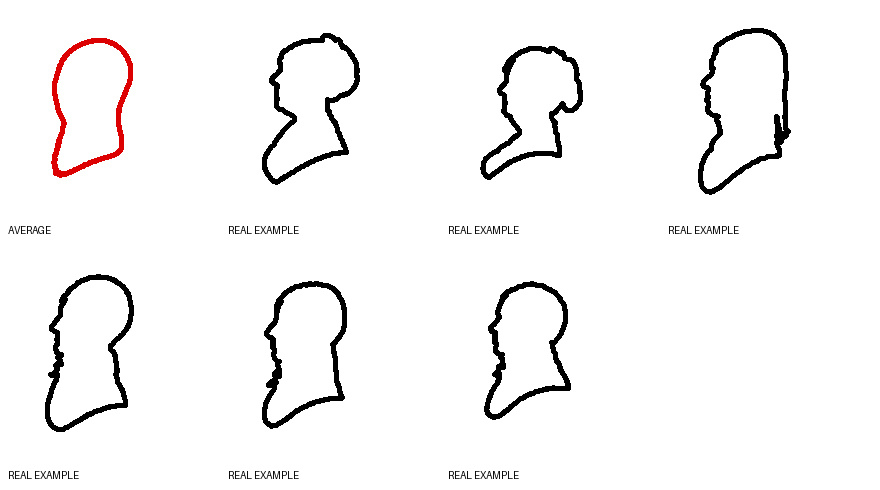

GROUP 7 | drawings: 203 | typical width: 920 | typical height: 1560 | typical width/height: 0.59


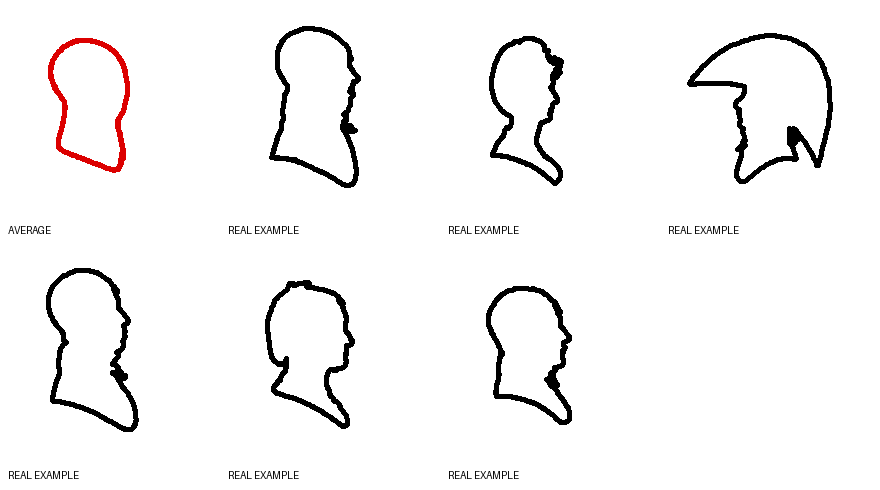

GROUP 8 | drawings: 254 | typical width: 872 | typical height: 1476 | typical width/height: 0.59


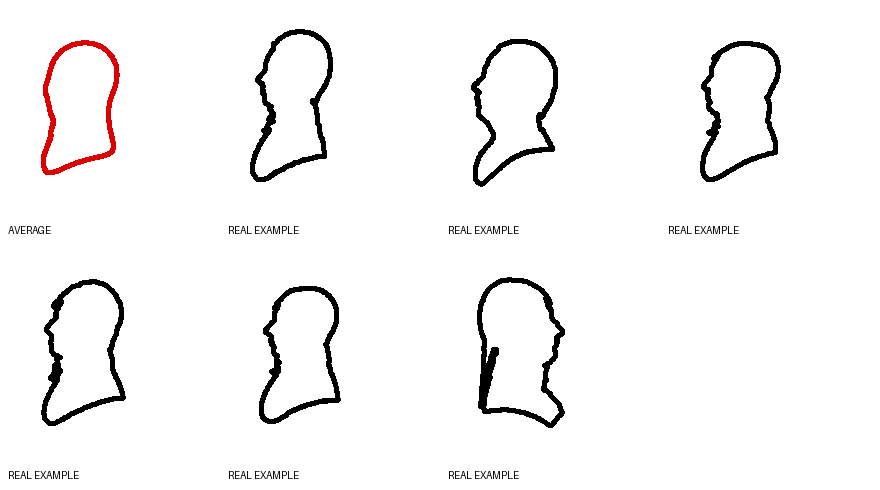

In [22]:
import numpy as np
from PIL import Image, ImageDraw

# Put every drawing back into (x, y) dot pairs
all_shapes = sil_xy_df.values.reshape(len(sil_xy_df), -1, 2)

# Set up the same drawing scale for every group
x_min = all_shapes[:, :, 0].min()
x_max = all_shapes[:, :, 0].max()
y_min = all_shapes[:, :, 1].min()
y_max = all_shapes[:, :, 1].max()

tile_size = 220
margin = 20
dot_radius = 2

def draw_shape(points, color=(0, 0, 0)):
    """Draw one silhouette in a square picture."""
    image = Image.new("RGB", (tile_size, tile_size), "white")
    draw = ImageDraw.Draw(image)

    scale = (tile_size - 2 * margin) / max(x_max - x_min, y_max - y_min)

    for x, y in points:
        px = margin + (x - x_min) * scale
        py = margin + (y - y_min) * scale
        draw.ellipse(
            (px - dot_radius, py - dot_radius,
             px + dot_radius, py + dot_radius),
            fill=color
        )

    return image

for group in range(n_clusters):
    # Get the row numbers of drawings in this group
    row_numbers = np.where(kmeans.labels_ == group)[0]
    group_shapes = all_shapes[row_numbers]

    # The average shape is the group's K-means center,
    # moved back to the original coordinate positions
    average_shape = kmeans.cluster_centers_[group].reshape(-1, 2) + xy_mean

    # Pick up to 6 real drawings from this group.
    # A fixed seed makes the examples stay the same each time you run it.
    rng = np.random.default_rng(100 + group)
    chosen_rows = rng.choice(
        row_numbers,
        size=min(6, len(row_numbers)),
        replace=False
    )

    # Calculate simple size measurements for the group
    widths = group_shapes[:, :, 0].max(axis=1) - group_shapes[:, :, 0].min(axis=1)
    heights = group_shapes[:, :, 1].max(axis=1) - group_shapes[:, :, 1].min(axis=1)
    ratios = widths / np.maximum(heights, 1)

    print(
        f"GROUP {group + 1} | drawings: {len(row_numbers)} | "
        f"typical width: {np.median(widths):.0f} | "
        f"typical height: {np.median(heights):.0f} | "
        f"typical width/height: {np.median(ratios):.2f}"
    )

    # Make a page: average first, then real examples
    pictures = [("AVERAGE", draw_shape(average_shape, color=(220, 0, 0)))]

    for row_number in chosen_rows:
        pictures.append(("REAL EXAMPLE", draw_shape(all_shapes[row_number])))

    columns = 4
    rows = (len(pictures) + columns - 1) // columns
    label_height = 25

    page = Image.new(
        "RGB",
        (columns * tile_size, rows * (tile_size + label_height)),
        "white"
    )
    page_draw = ImageDraw.Draw(page)

    for i, (label, picture) in enumerate(pictures):
        col = i % columns
        row = i // columns
        x = col * tile_size
        y = row * (tile_size + label_height)

        page.paste(picture, (x, y))
        page_draw.text((x + 8, y + tile_size + 4), label, fill="black")

    display(page)

In [23]:
import numpy as np
from PIL import Image, ImageDraw

all_shapes = sil_xy_df.values.reshape(len(sil_xy_df), -1, 2)
span = max(np.ptp(all_shapes[:, :, 0], axis=1).max(), np.ptp(all_shapes[:, :, 1], axis=1).max())

def draw_outline(points, tile=160, margin=10, color=(0, 0, 0)):
    img = Image.new("RGB", (tile, tile), "white")
    d = ImageDraw.Draw(img)
    scale = (tile - 2 * margin) / span
    mid = (points.min(axis=0) + points.max(axis=0)) / 2
    pts = [((x - mid[0]) * scale + tile / 2, (y - mid[1]) * scale + tile / 2) for x, y in points]
    d.line(pts + [pts[0]], fill=color, width=2)
    return img

def cluster_pages(model, data, n_show=20, cols=5, tile=160):
    dists = model.transform(data)
    pages = []
    for c in range(model.n_clusters):
        members = np.where(model.labels_ == c)[0]
        top = members[np.argsort(dists[members, c])][:n_show]
        rows = int(np.ceil(len(top) / cols))
        header = 30
        page = Image.new("RGB", (cols * tile, header + rows * tile), "white")
        label = f"Cluster {c + 1} | {len(members)} silhouettes | {len(top)} closest to center"
        ImageDraw.Draw(page).text((8, 8), label, fill="black")
        for i, idx in enumerate(top):
            page.paste(draw_outline(all_shapes[idx], tile), ((i % cols) * tile, header + (i // cols) * tile))
        pages.append(page)
    return pages

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


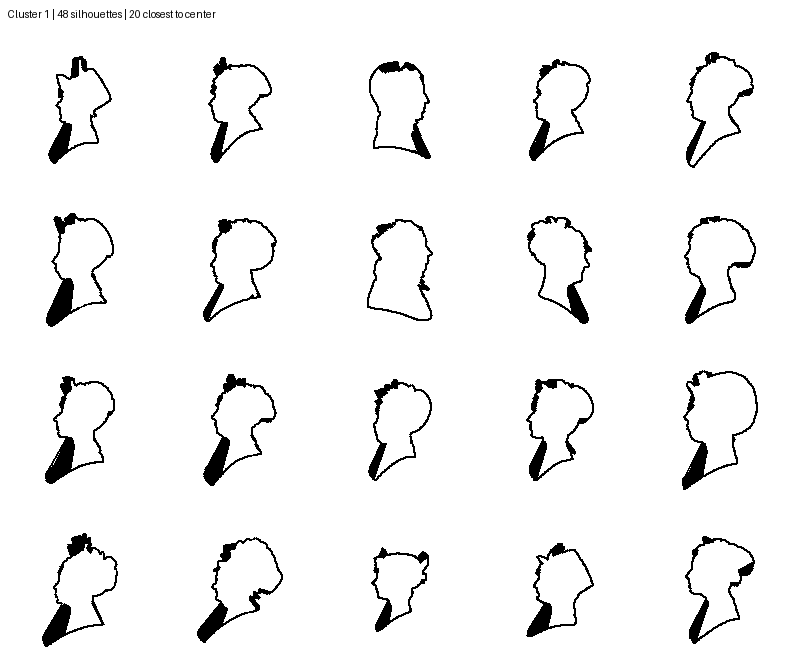

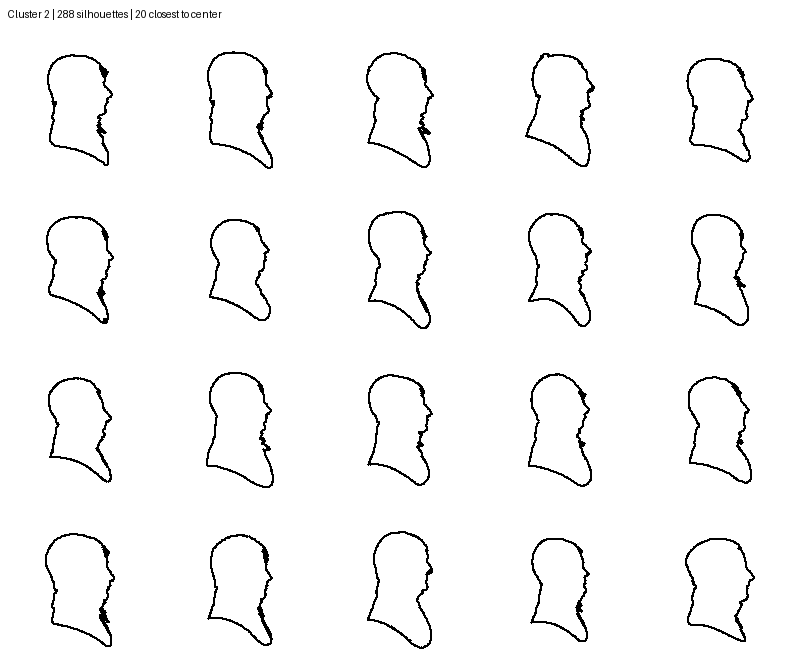

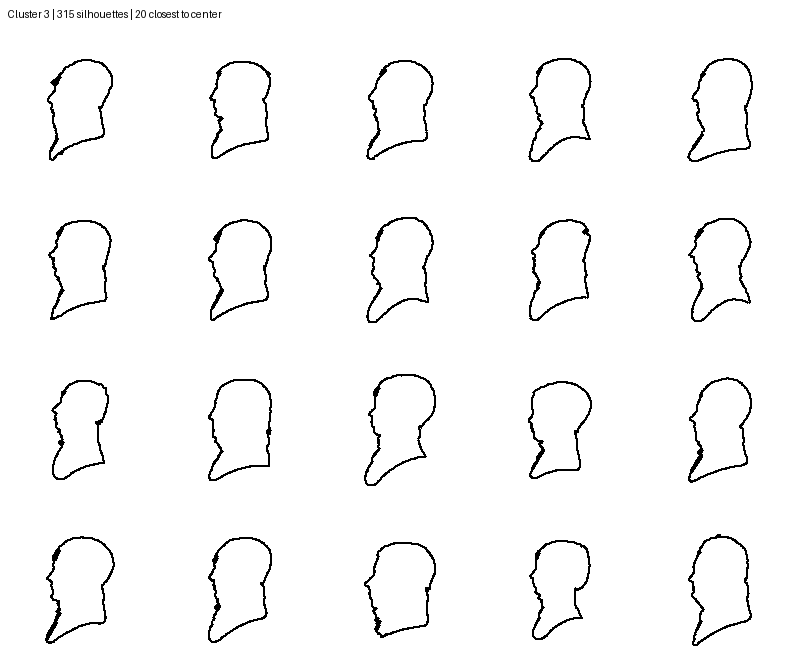

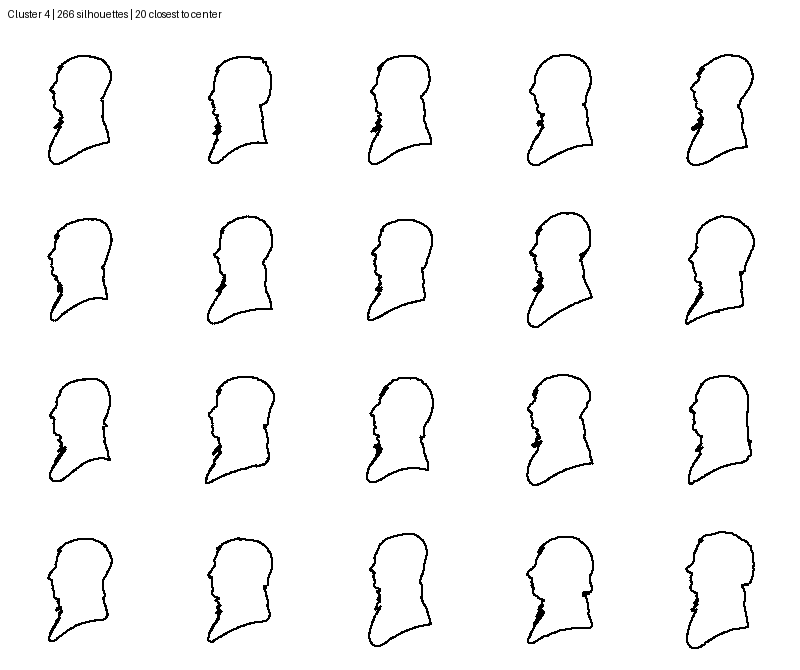

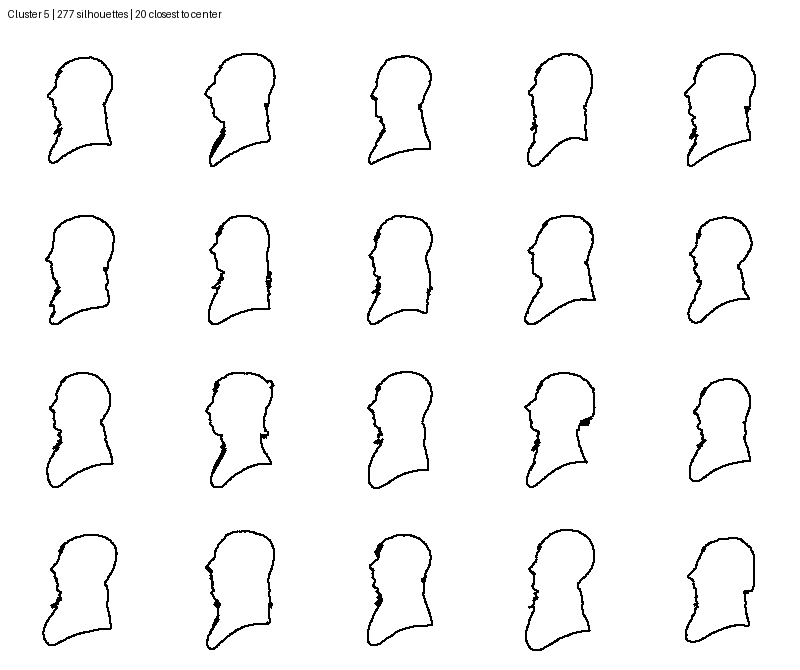

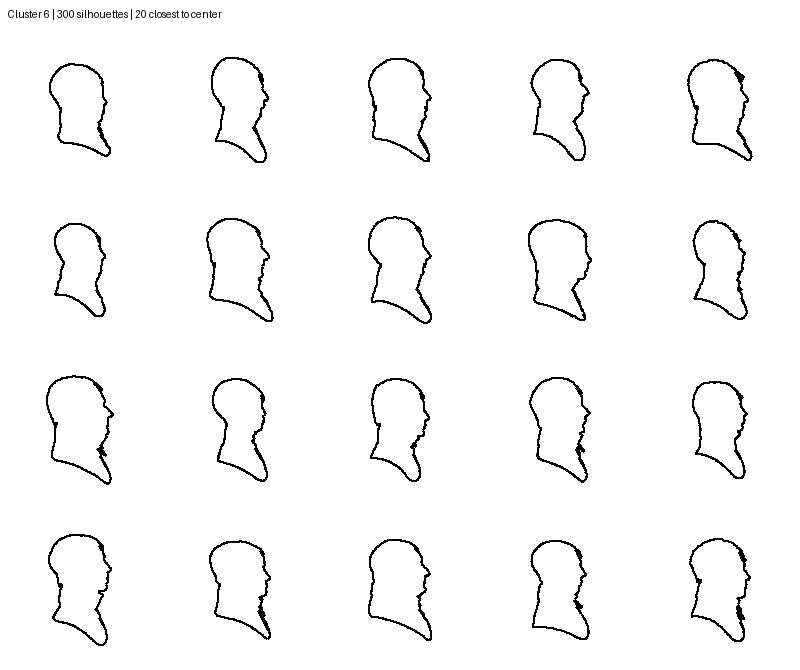

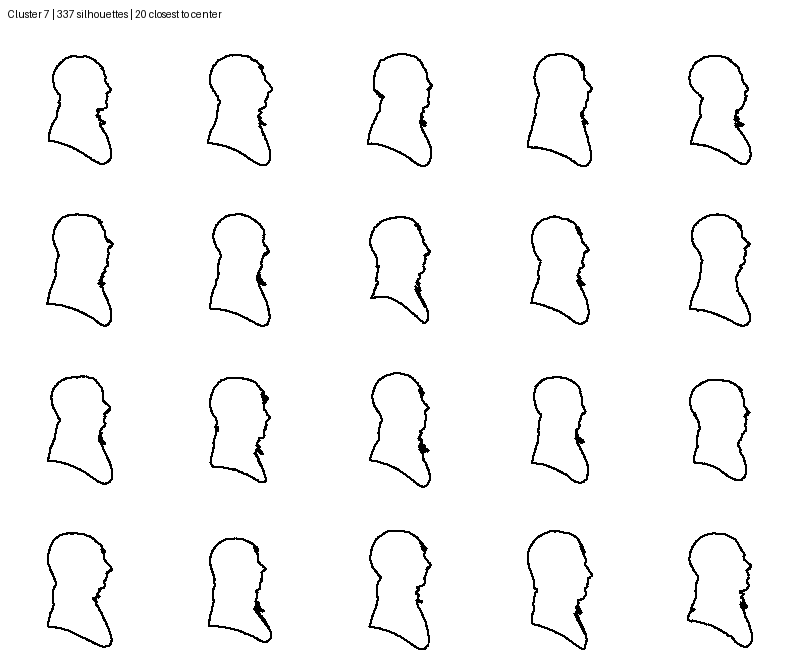

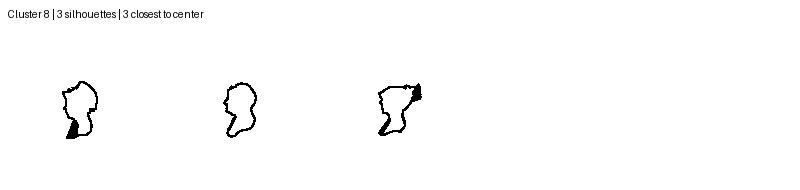

In [24]:
k = 8
km = KMeans(n_clusters=k, random_state=1010, n_init=10).fit(sil_xy_cetered_df)

for i, page in enumerate(cluster_pages(km, sil_xy_cetered_df)):
    page.save(f"cluster_{i + 1}.png")
    display(page)
    

In [25]:
from sklearn.metrics import silhouette_score

for k in range(4, 21, 2):
    km_k = KMeans(n_clusters=k, random_state=1010, n_init=10).fit(sil_xy_cetered_df)
    print(k, round(km_k.inertia_), round(silhouette_score(sil_xy_cetered_df, km_k.labels_), 3))

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

4 18103916320 0.144


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/pytho

6 16249388459 0.131


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/pytho

8 14934173657 0.114


... (7 outputs left out)

16 12338558328 0.102


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/pytho

18 11941328914 0.098
20 11635397565 0.093


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [26]:
%pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [27]:
import cv2
print(cv2.__version__)

5.0.0


In [28]:
import cv2
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def hu_features_for_shape(points, image_size=128, padding=8):
    points = np.asarray(points, dtype=np.float64)
    low = points.min(axis=0)
    high = points.max(axis=0)
    longest_side = max(high - low)

    if longest_side == 0:
        return np.zeros(7)

    scale = (image_size - 2 * padding) / longest_side
    polygon = np.rint((points - (low + high) / 2) * scale + image_size / 2)
    polygon = polygon.astype(np.int32)

    # White silhouette on a black background
    mask = np.zeros((image_size, image_size), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], 255)

    moments = cv2.moments(mask, binaryImage=True)
    hu = cv2.HuMoments(moments).flatten()

    # Compress the wide range of Hu values while retaining their signs
    return -np.sign(hu) * np.log10(np.maximum(np.abs(hu), 1e-30))

# One row per silhouette, seven Hu features per row
X_hu = np.vstack([hu_features_for_shape(shape) for shape in all_shapes])
X_hu_scaled = StandardScaler().fit_transform(X_hu)

print("Feature matrix:", X_hu_scaled.shape)

Feature matrix: (1834, 7)


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountere

Cluster sizes: [323 454 108 386  39 360   1 163]
Inertia: 3470.876777694898
Silhouette score: 0.3362879056959636


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


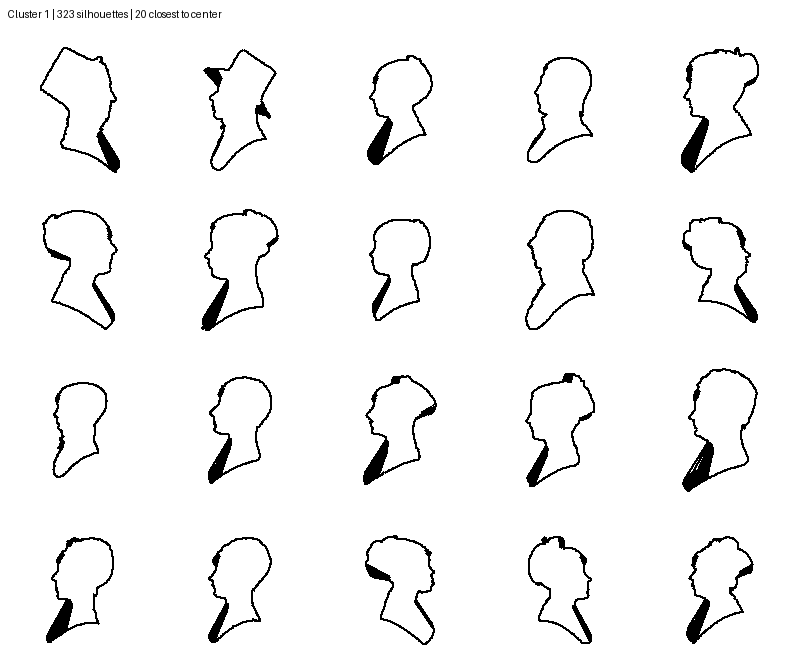

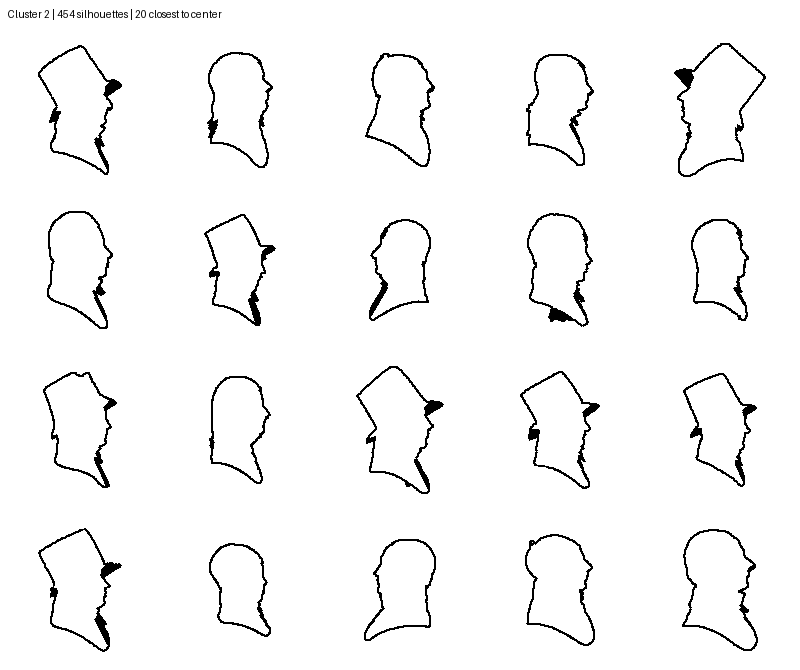

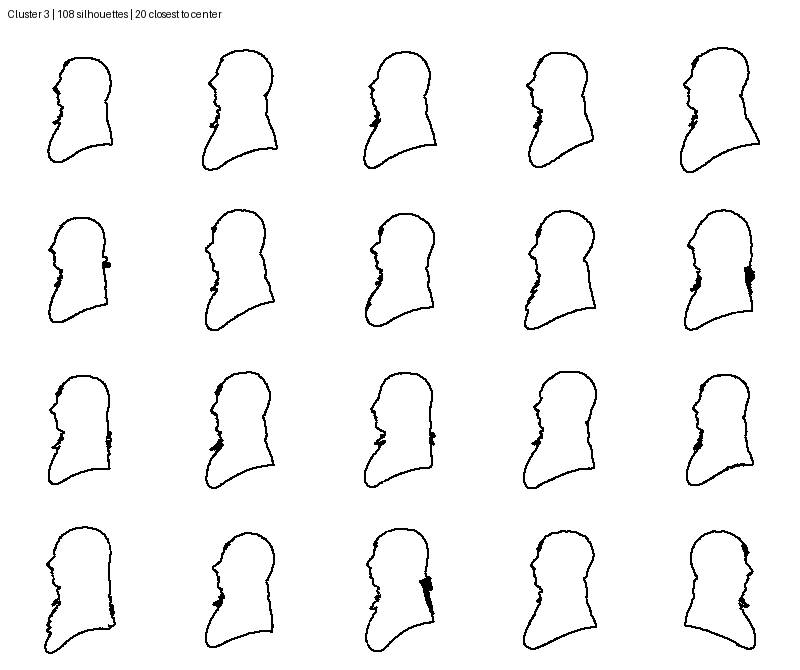

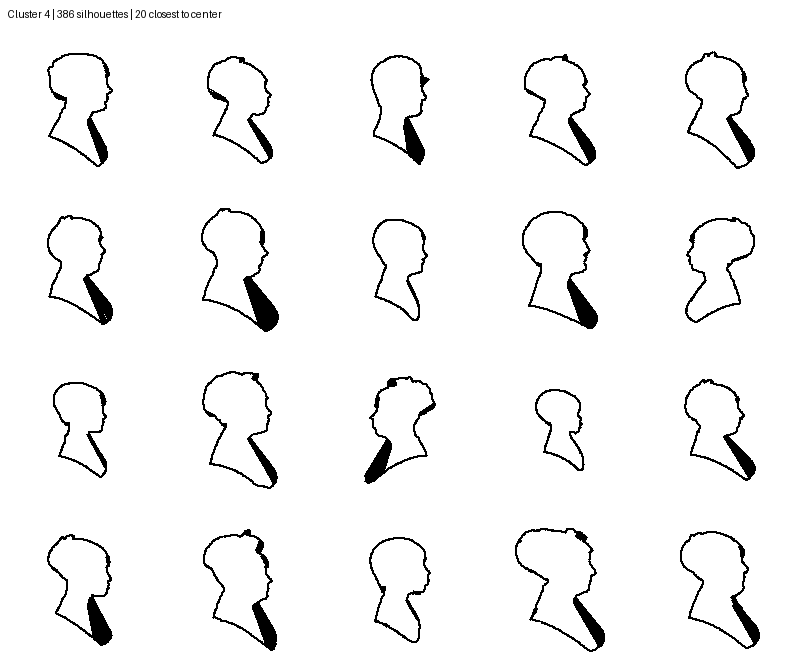

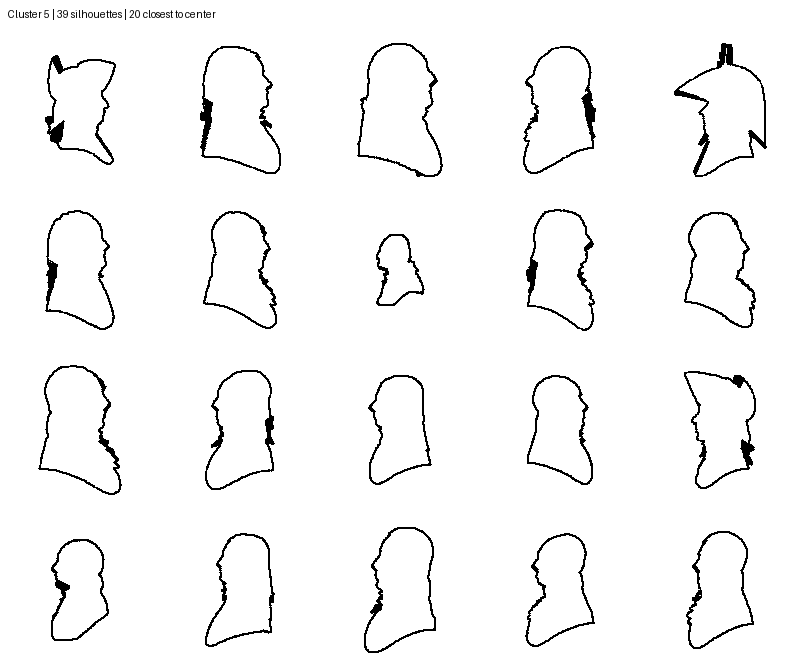

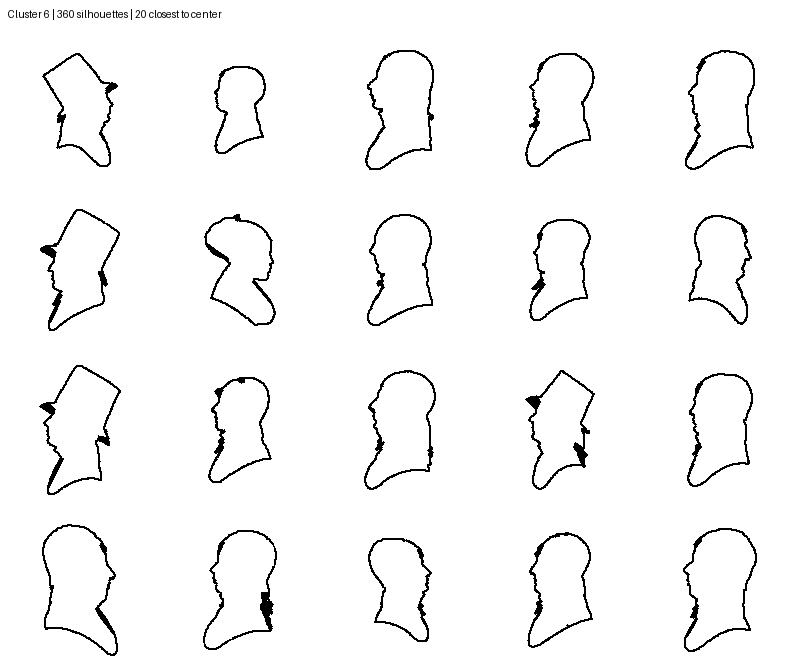

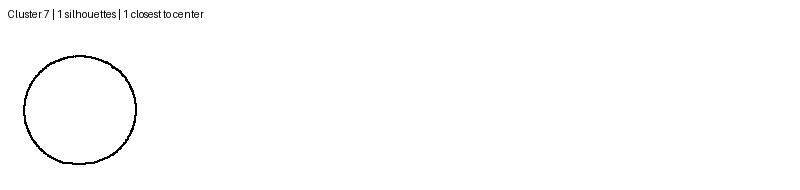

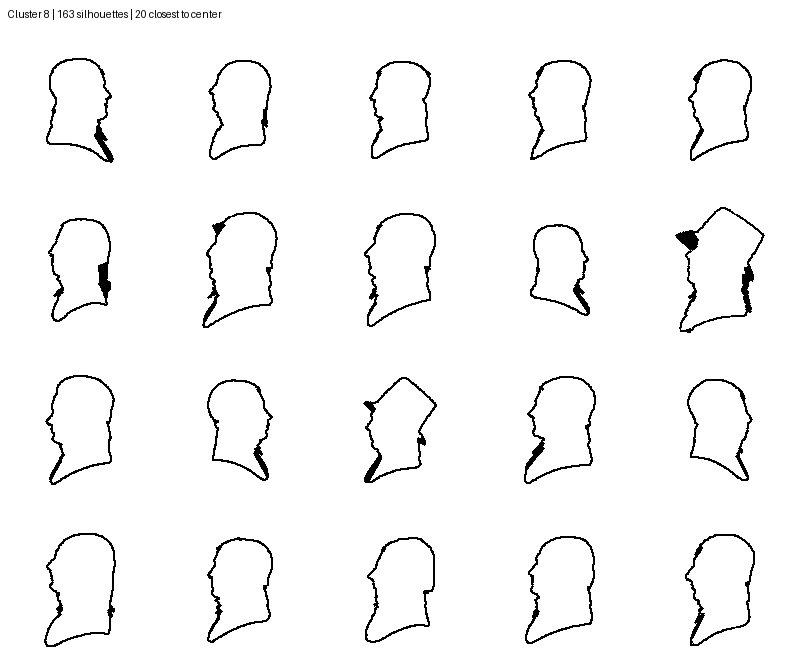

In [29]:
k = 8  # Try 4, 6, or 8
hu_kmeans = KMeans(
    n_clusters=k,
    random_state=1010,
    n_init=10
).fit(X_hu_scaled)

print("Cluster sizes:", np.bincount(hu_kmeans.labels_))
print("Inertia:", hu_kmeans.inertia_)
print("Silhouette score:", silhouette_score(X_hu_scaled, hu_kmeans.labels_))

for page in cluster_pages(hu_kmeans, X_hu_scaled, n_show=20):
    display(page)

In [3]:
import pandas as pd
from datasets import load_dataset

sil_ds = load_dataset(
    "visualizedata/revolutionary_silhouettes",
    split="silhouetted",
    streaming=True
)

xy_features = [
    name for name in sil_ds.features.keys()
    if name.startswith(("x", "y"))
]

sil_xy_ds = sil_ds.select_columns(xy_features)

sil_xy_df = pd.concat(
    sil_xy_ds.to_pandas(batched=True),
    ignore_index=True
)

print(sil_xy_df.shape)

/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


(1834, 946)


Number of clusters: 8
Cluster sizes: [569, 454, 203, 186, 333, 3, 34, 52]
Silhouette score: 0.103


/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/trishamohite/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


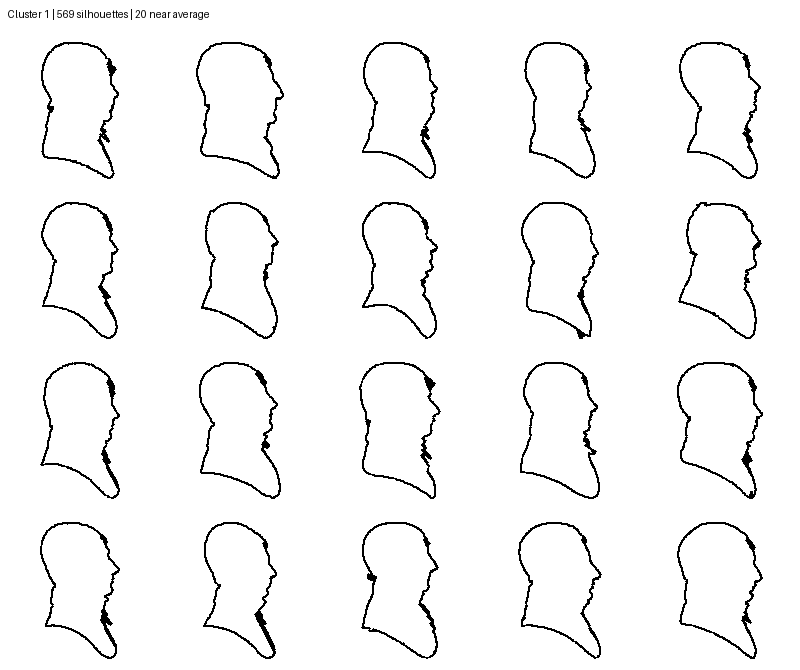

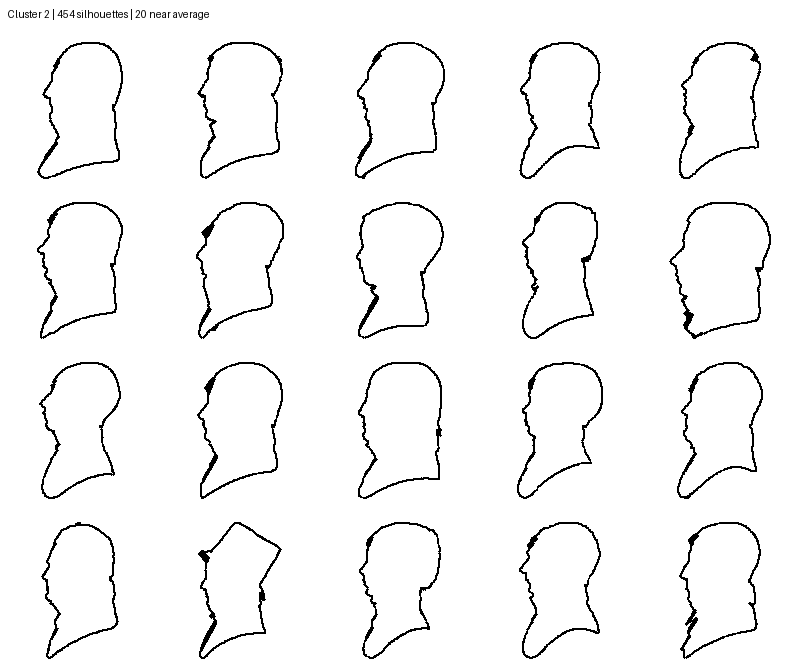

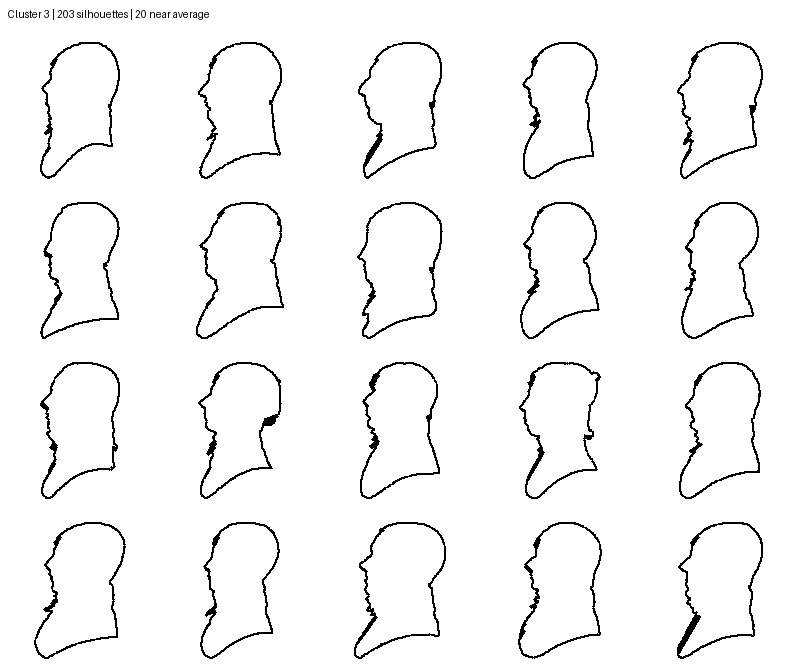

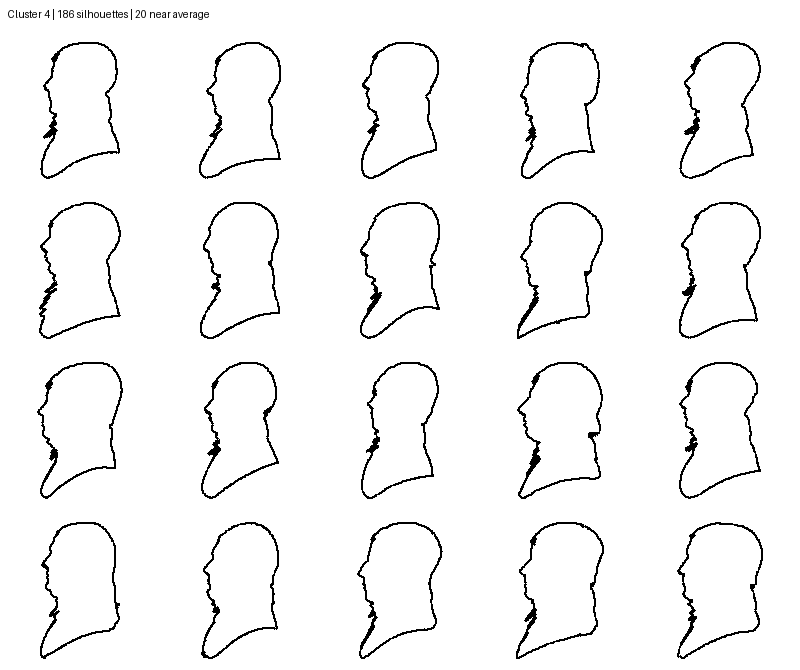

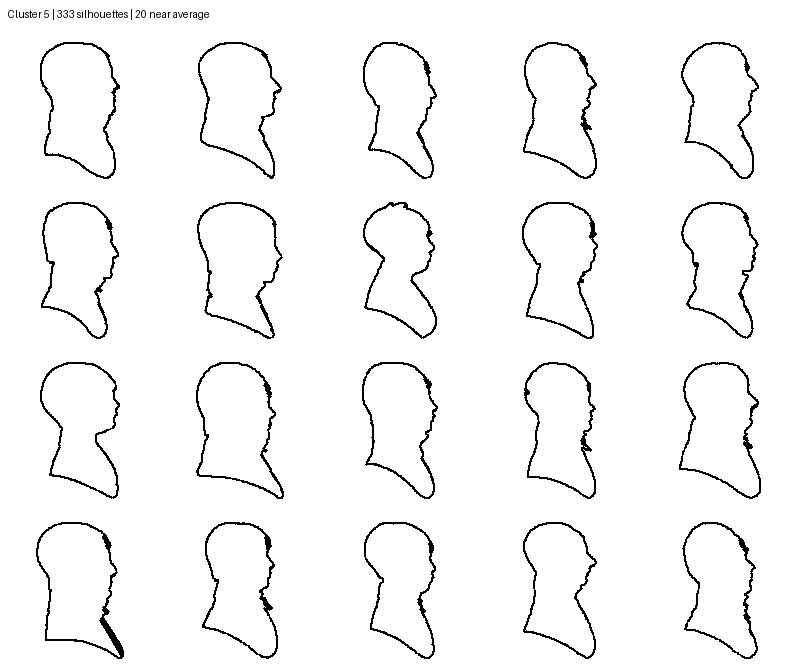

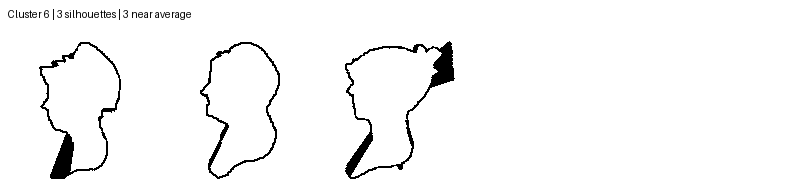

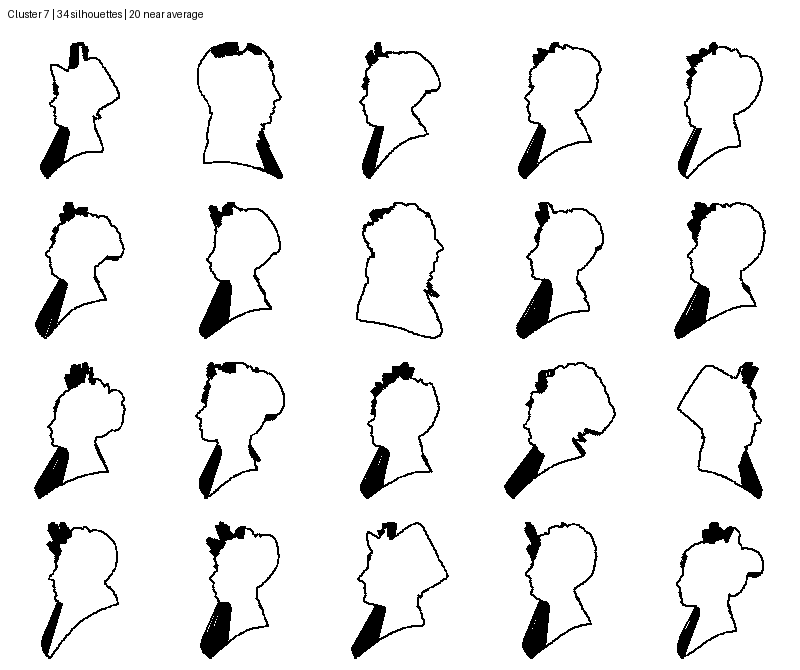

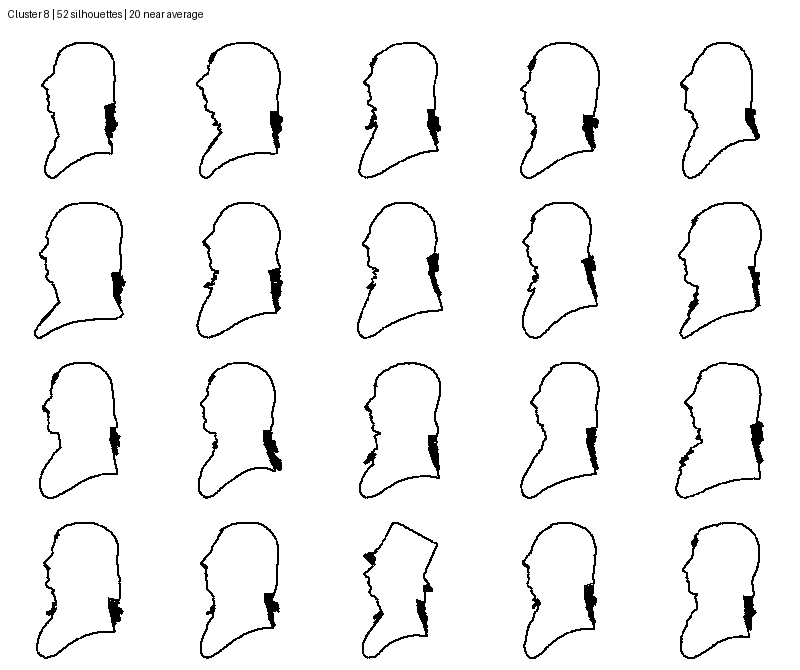

In [4]:
import numpy as np
from PIL import Image, ImageDraw
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Rebuild the coordinate data.
# Each row becomes one silhouette with 473 (x, y) points.
all_shapes = sil_xy_df.to_numpy(dtype=np.float64).reshape(
    len(sil_xy_df), -1, 2
)

# Subtract the same overall mean used earlier in the notebook.
# This does not align silhouettes individually; it just recenters the
# entire dataset. The cluster assignments are unaffected by this shift.
xy_mean = all_shapes.mean(axis=1).mean(axis=0)
X_coords = (all_shapes - xy_mean).reshape(len(all_shapes), -1)

# Choose how many clusters to make.
k = 8  # Try 4, 6, and 8

# Fit agglomerative clustering.
agglo = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)
agglo_labels = agglo.fit_predict(X_coords)

# Print the number of silhouettes in each cluster and the overall score.
cluster_sizes = np.bincount(agglo_labels)
score = silhouette_score(X_coords, agglo_labels)

print(f"Number of clusters: {k}")
print("Cluster sizes:", cluster_sizes.tolist())
print(f"Silhouette score: {score:.3f}")

# Draw one silhouette centered and scaled inside a tile.
def draw_outline(points, tile=160, margin=12):
    image = Image.new("RGB", (tile, tile), "white")
    draw = ImageDraw.Draw(image)

    points = np.asarray(points, dtype=np.float64)
    low = points.min(axis=0)
    high = points.max(axis=0)
    center = (low + high) / 2
    size = high - low

    longest_side = max(size)
    if longest_side == 0:
        return image

    scale = (tile - 2 * margin) / longest_side
    placed = (points - center) * scale + tile / 2
    placed = [tuple(point) for point in placed]

    # Connect the contour points and close the outline.
    draw.line(placed + [placed[0]], fill="black", width=2)
    return image

# Make a page per cluster showing up to 20 members nearest its average
# coordinate vector. Agglomerative clustering has no K-means center, so
# the average here is only used to choose representative examples.
def make_agglomerative_pages(labels, features, shapes, n_show=20, cols=5, tile=160):
    pages = []

    for cluster_id in np.unique(labels):
        members = np.where(labels == cluster_id)[0]
        cluster_average = features[members].mean(axis=0)

        distances = np.linalg.norm(
            features[members] - cluster_average,
            axis=1
        )
        nearest_members = members[np.argsort(distances)[:n_show]]

        rows = int(np.ceil(len(nearest_members) / cols))
        header_height = 30

        page = Image.new(
            "RGB",
            (cols * tile, header_height + rows * tile),
            "white"
        )

        ImageDraw.Draw(page).text(
            (8, 8),
            f"Cluster {cluster_id + 1} | {len(members)} silhouettes "
            f"| {len(nearest_members)} near average",
            fill="black"
        )

        for i, row_number in enumerate(nearest_members):
            col = i % cols
            row = i // cols
            page.paste(
                draw_outline(shapes[row_number], tile=tile),
                (col * tile, header_height + row * tile)
            )

        pages.append(page)

    return pages

# Display the pages.
for page in make_agglomerative_pages(
    agglo_labels,
    X_coords,
    all_shapes,
    n_show=20
):
    display(page)